Q1

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Words: ['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'rapidly', 'machines', 'can', 'learn', 'from', 'data', 'and', 'solve', 'complex', 'problems', 'students', 'use', 'technology', 'to', 'improve', 'their', 'learning', 'learning', 'new', 'skills', 'helps', 'people', 'build', 'better', 'careers', 'computers', 'are', 'becoming', 'smarter', 'every', 'day', 'technology', 'makes', 'our', 'lives', 'easier', 'and', 'more', 'productive']
Sentences: ['artificial intelligence is changing the world rapidly.', 'machines can learn from data and solve complex problems.', 'students use technology to improve their learning.', 'learning new skills helps people build better careers.', 'computers are becoming smarter every day.', 'technology makes our lives easier and more productive.']
Using split(): ['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'rapidly', 'machines', 'can', 'learn', 'from', 'data', 'and', 'solve', 'complex', 'problems', 'students', 'use', 'technolog

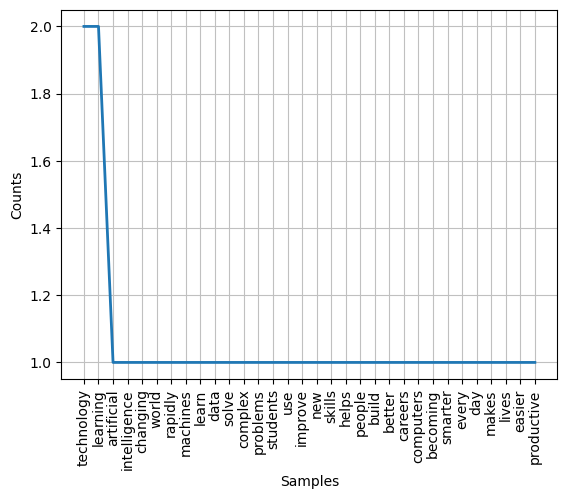

In [3]:
import re
import nltk
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

original_text = """Artificial intelligence is changing the world rapidly.
Machines can learn from data and solve complex problems.
Students use technology to improve their learning.
Learning new skills helps people build better careers.
Computers are becoming smarter every day.
Technology makes our lives easier and more productive."""

text = original_text.lower()
text = re.sub(r'[^\w\s]', '', text)

words = word_tokenize(text)
sentences = sent_tokenize(original_text.lower())

print("Words:", words)
print("Sentences:", sentences)

print("Using split():", text.split())
print("Using word_tokenize():", word_tokenize(text))
# split() only breaks on whitespace, so punctuation stays attached to words ("rapidly." stays as one token).
# word_tokenize() separates punctuation into its own tokens and handles contractions ("don't" becomes "do" and "n't").

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

print("After removing stopwords:", filtered_words)

fdist = FreqDist(filtered_words)
print("Word frequency:", fdist)
print("Frequency list:", fdist.most_common())

fdist.plot()
plt.show()

Q2

In [4]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

words = re.findall(r'\b[a-zA-Z]+\b', text)

print("Words containing only alphabets:", words)

stop_words = set(stopwords.words('english'))
filtered_words = []

for word in words:
    if word not in stop_words:
        filtered_words.append(word)

print("After removing stopwords:", filtered_words)

ps = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_words = []
lemmatized_words = []

for word in filtered_words:
    stemmed_words.append(ps.stem(word))
    lemmatized_words.append(lemmatizer.lemmatize(word))

print("Stemmed words:", stemmed_words)
print("Lemmatized words:", lemmatized_words)

# Stemming chops suffixes by rules and can produce non-words, as in your output ("artifici", "intellig", "rapidli", "everi").
# Lemmatization uses a dictionary and returns real words ("life", "people", "computer").
# Prefer stemming when speed matters and exact words don't, as in search or indexing.
# Prefer lemmatization when the output must be real words with correct meaning, as in chatbots and text analysis.

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Words containing only alphabets: ['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'rapidly', 'machines', 'can', 'learn', 'from', 'data', 'and', 'solve', 'complex', 'problems', 'students', 'use', 'technology', 'to', 'improve', 'their', 'learning', 'learning', 'new', 'skills', 'helps', 'people', 'build', 'better', 'careers', 'computers', 'are', 'becoming', 'smarter', 'every', 'day', 'technology', 'makes', 'our', 'lives', 'easier', 'and', 'more', 'productive']
After removing stopwords: ['artificial', 'intelligence', 'changing', 'world', 'rapidly', 'machines', 'learn', 'data', 'solve', 'complex', 'problems', 'students', 'use', 'technology', 'improve', 'learning', 'learning', 'new', 'skills', 'helps', 'people', 'build', 'better', 'careers', 'computers', 'becoming', 'smarter', 'every', 'day', 'technology', 'makes', 'lives', 'easier', 'productive']
Stemmed words: ['artifici', 'intellig', 'chang', 'world', 'rapidli', 'machin', 'learn', 'data', 'solv', 'complex', 'problem', 'stu

Q3

In [6]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "This phone has a great camera and good battery life.",
    "The laptop has a fast processor and good battery life.",
    "The camera takes clear photos and the phone works well."
]

cv = CountVectorizer()
bow = cv.fit_transform(texts)

print("Bag of Words:")
print(cv.get_feature_names_out())
print(bow.toarray())

tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(texts)

words = tfidf.get_feature_names_out()
scores = tfidf_matrix.toarray()

print("\nTF-IDF Scores:")
print(words)
print(scores)

print("\nTop 3 keywords from each text:")

for i in range(len(texts)):
    word_scores = list(zip(words, scores[i]))
    word_scores.sort(key=lambda x: x[1], reverse=True)

    print("\nText", i + 1, ":", texts[i])
    for word, score in word_scores[:3]:
        print(word, ":", round(score, 3))
# A high TF-IDF score means the word appears in that text but is rare in the others.
# Words shared across texts ("good", "battery", "phone") score lower.
# In Text 2, "laptop", "fast" and "processor" are tied at 0.46 and describe it best.

Bag of Words:
['and' 'battery' 'camera' 'clear' 'fast' 'good' 'great' 'has' 'laptop'
 'life' 'phone' 'photos' 'processor' 'takes' 'the' 'this' 'well' 'works']
[[1 1 1 0 0 1 1 1 0 1 1 0 0 0 0 1 0 0]
 [1 1 0 0 1 1 0 1 1 1 0 0 1 0 1 0 0 0]
 [1 0 1 1 0 0 0 0 0 0 1 1 0 1 2 0 1 1]]

TF-IDF Scores:
['battery' 'camera' 'clear' 'fast' 'good' 'great' 'laptop' 'life' 'phone'
 'photos' 'processor' 'takes' 'works']
[[0.38550292 0.38550292 0.         0.         0.38550292 0.50689001
  0.         0.38550292 0.38550292 0.         0.         0.
  0.        ]
 [0.34949812 0.         0.         0.45954803 0.34949812 0.
  0.45954803 0.34949812 0.         0.         0.45954803 0.
  0.        ]
 [0.         0.3349067  0.44036207 0.         0.         0.
  0.         0.         0.3349067  0.44036207 0.         0.44036207
  0.44036207]]

Top 3 keywords from each text:

Text 1 : This phone has a great camera and good battery life.
great : 0.507
battery : 0.386
camera : 0.386

Text 2 : The laptop has a fast pro

Q4

In [7]:
import re
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

nltk.download('stopwords')

text1 = """Artificial intelligence allows computers to learn from data.
AI can solve problems and make decisions.
It is used in healthcare, education and business.
Machine learning helps improve AI systems."""

text2 = """Blockchain stores data in secure digital blocks.
It allows transactions without a central authority.
Blockchain is used in cryptocurrency and finance.
It provides transparency and security."""

stop_words = set(stopwords.words('english'))

words1 = re.findall(r'\b[a-zA-Z]+\b', text1.lower())
words2 = re.findall(r'\b[a-zA-Z]+\b', text2.lower())

words1 = [word for word in words1 if word not in stop_words]
words2 = [word for word in words2 if word not in stop_words]

print("Text 1 tokens:", words1)
print("Text 2 tokens:", words2)

set1 = set(words1)
set2 = set(words2)

jaccard = len(set1.intersection(set2)) / len(set1.union(set2))

print("Jaccard Similarity:", jaccard)

texts = [text1, text2]

vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform(texts)

cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])

print("Cosine Similarity:", cosine[0][0])
# Jaccard only counts shared unique words and ignores how often they appear.
# Cosine on TF-IDF weights words by importance. Here both are low (about 0.08), which correctly shows the two topics are different.
# Cosine is usually better because it accounts for word weights.

Text 1 tokens: ['artificial', 'intelligence', 'allows', 'computers', 'learn', 'data', 'ai', 'solve', 'problems', 'make', 'decisions', 'used', 'healthcare', 'education', 'business', 'machine', 'learning', 'helps', 'improve', 'ai', 'systems']
Text 2 tokens: ['blockchain', 'stores', 'data', 'secure', 'digital', 'blocks', 'allows', 'transactions', 'without', 'central', 'authority', 'blockchain', 'used', 'cryptocurrency', 'finance', 'provides', 'transparency', 'security']
Jaccard Similarity: 0.08823529411764706
Cosine Similarity: 0.07822065480751297


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Q5

Review: This phone is amazing and the camera quality is excellent.
Polarity: 0.8
Subjectivity: 0.95
Sentiment: Positive

Review: The product is very good and easy to use.
Polarity: 0.6716666666666666
Subjectivity: 0.8066666666666668
Sentiment: Positive

Review: I am happy with the battery life and performance.
Polarity: 0.8
Subjectivity: 1.0
Sentiment: Positive

Review: The product is bad and the quality is poor.
Polarity: -0.5499999999999999
Subjectivity: 0.6333333333333333
Sentiment: Negative

Review: I am disappointed with this phone.
Polarity: -0.75
Subjectivity: 0.75
Sentiment: Negative

Review: The product is neither good nor bad.
Polarity: 5.551115123125783e-17
Subjectivity: 0.6333333333333333
Sentiment: Neutral



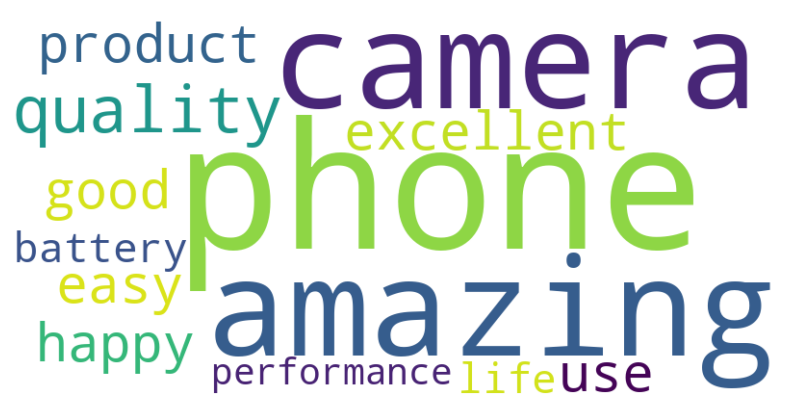

In [14]:
import nltk
import matplotlib.pyplot as plt
from textblob import TextBlob
from wordcloud import WordCloud

reviews = [
    "This phone is amazing and the camera quality is excellent.",
    "The product is very good and easy to use.",
    "I am happy with the battery life and performance.",
    "The product is bad and the quality is poor.",
    "I am disappointed with this phone.",
    "The product is neither good nor bad."
]

positive_reviews = []

for review in reviews:
    analysis = TextBlob(review)
    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity

    if polarity > 0.1:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("Review:", review)
    print("Polarity:", polarity)
    print("Subjectivity:", subjectivity)
    print("Sentiment:", sentiment)
    print()

positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(width=800, height=400, background_color="white")
wordcloud.generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

Q6

In [19]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """football is a popular sport in the world
players practice every day to improve their skills
a team has eleven players on the field
the goalkeeper protects the goal from the other team
players pass the ball to score goals
good teamwork helps players win matches
coaches train players and plan strategies
fans support their favorite team during every game
the referee makes decisions and ensures fair play
football teaches teamwork and discipline"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])
total_words = len(tokenizer.word_index) + 1

sequences = []
for line in text.split("\n"):
    numbers = tokenizer.texts_to_sequences([line])[0]
    for i in range(2, len(numbers) + 1):
        sequences.append(numbers[:i])

max_length = max(len(s) for s in sequences)
sequences = pad_sequences(sequences, maxlen=max_length)

X = sequences[:, :-1]
y = sequences[:, -1]

model = Sequential()
model.add(Embedding(total_words, 16))
model.add(LSTM(64))
model.add(Dense(total_words, activation="softmax"))

model.compile(loss="sparse_categorical_crossentropy", optimizer="adam")

model.fit(X, y, epochs=200, verbose=0)

def generate_text(seed, num_words):
    text_so_far = seed
    for _ in range(num_words):
        numbers = tokenizer.texts_to_sequences([text_so_far])[0]
        numbers = pad_sequences([numbers], maxlen=max_length - 1)
        prediction = model.predict(numbers, verbose=0)
        next_index = np.argmax(prediction)
        text_so_far = text_so_far + " " + tokenizer.index_word[next_index]
    return text_so_far

print(generate_text("football", 4))
print(generate_text("players", 4))
print(generate_text("the", 4))

football teamwork a players discipline
players pass the ball to
the referee makes decisions and
